# Group Members:
### 1. Hoor-ul-ain Wajid (B22F0068DS004)
### 2. Maheen Shahid (B22F0944DS025)
# Instructor:  Mr Usama Ahmed
# Lab engineer: Mr Fahad Qureshi
# Program: BS. Data Science
# Course: Data Mining
# Semester: 5th




# Space Mission Dataset
This dataset is a synthetic representation of space missions, designed to provide insights into various aspects of space exploration. It includes simulated data on mission details, launch dates, destinations, spacecraft specifications, mission outcomes, and more. While not based on real missions, the dataset offers a structured and realistic framework for analysis, making it ideal for research, machine learning projects, and educational purposes.

1. Mission ID: A unique identifier for each space mission.
2. Mission Name: The name assigned to the space mission.
3. Launch Date: The date on which the mission was launched.
4. Target Type: The category of the celestial body targeted by the mission.
5. Target Name: The specific name of the celestial body targeted by the mission.
6. Mission Type: The primary objective or goal of the mission.
7. Distance from Earth (light-years): The distance of the target from Earth in light-years.
8. Mission Duration (years): The total time taken for the mission, measured in years.
9. Mission Cost (billion USD): The cost of the mission in billions of US dollars.
10. Scientific Yield (points): A measure of the mission's scientific output or value.
11. Crew Size: The number of crew members involved in the mission.
12. Mission Success (%): The probability of mission success, expressed as a percentage.
13. Fuel Consumption (tons): The total amount of fuel used during the mission, measured in tons.
14. Payload Weight (tons): The weight of the payload carried by the mission, measured in tons.
15. Launch Vehicle: The type or name of the rocket or spacecraft used to launch the mission.

# Setting Pyspark Environment

In [1]:
!apt-get install openjdk-8-jdk-headless -qq > /dev/null
!wget -q http://archive.apache.org/dist/spark/spark-3.5.1/spark-3.5.1-bin-hadoop3.tgz
!tar xf spark-3.5.1-bin-hadoop3.tgz
!pip install -q findspark

In [2]:
import os
os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-8-openjdk-amd64"
os.environ["SPARK_HOME"] = "/content/spark-3.5.1-bin-hadoop3"

In [3]:
import findspark
findspark.init()
from pyspark.sql import SparkSession
spark = SparkSession.builder.master("local[*]").getOrCreate()
spark.conf.set("spark.sql.repl.eagerEval.enabled", True) # Property used to format output tables better
spark

# Loading Necessary Librararies

In [4]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from pyspark.sql.functions import year
from pyspark.sql.functions import expr
from pyspark.ml.clustering import KMeans
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.regression import LinearRegression
from pyspark.sql.functions import col, when, count
from pyspark.ml.evaluation import RegressionEvaluator
from pyspark.ml.regression import DecisionTreeRegressor
from pyspark.ml.evaluation import ClusteringEvaluator
from pyspark.sql.types import DoubleType, IntegerType, DateType
from pyspark.sql.types import StructType, StructField, StringType


# Load Dataset

In [5]:
df = spark.read.csv('/content/space_missions_dataset.csv', header=True)
df.show(5)

+----------+------------+-----------+-----------+-----------+------------+---------------------------------+------------------------+--------------------------+-------------------------+---------+-------------------+-----------------------+---------------------+--------------+
|Mission ID|Mission Name|Launch Date|Target Type|Target Name|Mission Type|Distance from Earth (light-years)|Mission Duration (years)|Mission Cost (billion USD)|Scientific Yield (points)|Crew Size|Mission Success (%)|Fuel Consumption (tons)|Payload Weight (tons)|Launch Vehicle|
+----------+------------+-----------+-----------+-----------+------------+---------------------------------+------------------------+--------------------------+-------------------------+---------+-------------------+-----------------------+---------------------+--------------+
|  MSN-0001|   Mission-1| 2025-01-01|       Star|      Titan|Colonization|                             7.05|                     5.2|                    526.68|      

# Data Pre-processing and Cleaning

In [6]:
df.printSchema()

root
 |-- Mission ID: string (nullable = true)
 |-- Mission Name: string (nullable = true)
 |-- Launch Date: string (nullable = true)
 |-- Target Type: string (nullable = true)
 |-- Target Name: string (nullable = true)
 |-- Mission Type: string (nullable = true)
 |-- Distance from Earth (light-years): string (nullable = true)
 |-- Mission Duration (years): string (nullable = true)
 |-- Mission Cost (billion USD): string (nullable = true)
 |-- Scientific Yield (points): string (nullable = true)
 |-- Crew Size: string (nullable = true)
 |-- Mission Success (%): string (nullable = true)
 |-- Fuel Consumption (tons): string (nullable = true)
 |-- Payload Weight (tons): string (nullable = true)
 |-- Launch Vehicle: string (nullable = true)



### Here all columns are converted to string datatype despite  some being numeric columns

# Explicit type casting to convert from string to numerical

In [7]:
# Convert columns to their original data types
df = (
    df
    .withColumn("Launch Date", df["Launch Date"].cast(DateType()))
    .withColumn("Distance from Earth (light-years)", df["Distance from Earth (light-years)"].cast(DoubleType()))
    .withColumn("Mission Duration (years)", df["Mission Duration (years)"].cast(DoubleType()))
    .withColumn("Mission Cost (billion USD)", df["Mission Cost (billion USD)"].cast(DoubleType()))
    .withColumn("Scientific Yield (points)", df["Scientific Yield (points)"].cast(DoubleType()))
    .withColumn("Crew Size", df["Crew Size"].cast(IntegerType()))
    .withColumn("Mission Success (%)", df["Mission Success (%)"].cast(DoubleType()))
    .withColumn("Fuel Consumption (tons)", df["Fuel Consumption (tons)"].cast(DoubleType()))
    .withColumn("Payload Weight (tons)", df["Payload Weight (tons)"].cast(DoubleType()))
)

# Print schema to verify changes
df.printSchema()


root
 |-- Mission ID: string (nullable = true)
 |-- Mission Name: string (nullable = true)
 |-- Launch Date: date (nullable = true)
 |-- Target Type: string (nullable = true)
 |-- Target Name: string (nullable = true)
 |-- Mission Type: string (nullable = true)
 |-- Distance from Earth (light-years): double (nullable = true)
 |-- Mission Duration (years): double (nullable = true)
 |-- Mission Cost (billion USD): double (nullable = true)
 |-- Scientific Yield (points): double (nullable = true)
 |-- Crew Size: integer (nullable = true)
 |-- Mission Success (%): double (nullable = true)
 |-- Fuel Consumption (tons): double (nullable = true)
 |-- Payload Weight (tons): double (nullable = true)
 |-- Launch Vehicle: string (nullable = true)



# Dataframe's Shape

In [8]:
print("Number of records in dataset:",df.count())
print("Number of columns in dataset:",len(df.columns))

Number of records in dataset: 500
Number of columns in dataset: 15


# Check For Null Values

In [9]:
# Check if any column has null values
df.select([count(when(col(c).isNull(), c)).alias(c) for c in df.columns]).show()

+----------+------------+-----------+-----------+-----------+------------+---------------------------------+------------------------+--------------------------+-------------------------+---------+-------------------+-----------------------+---------------------+--------------+
|Mission ID|Mission Name|Launch Date|Target Type|Target Name|Mission Type|Distance from Earth (light-years)|Mission Duration (years)|Mission Cost (billion USD)|Scientific Yield (points)|Crew Size|Mission Success (%)|Fuel Consumption (tons)|Payload Weight (tons)|Launch Vehicle|
+----------+------------+-----------+-----------+-----------+------------+---------------------------------+------------------------+--------------------------+-------------------------+---------+-------------------+-----------------------+---------------------+--------------+
|         0|           0|          0|          0|          0|           0|                                0|                       0|                         0|      

# Drop Duplicates if Any

In [10]:
df =df.dropDuplicates()


# Removing Outliers

In [11]:
#Remove outliers using IQR
for col_name in ["Distance from Earth (light-years)","Mission Duration (years)","Mission Cost (billion USD)","Scientific Yield (points)","Crew Size",
    "Mission Success (%)","Fuel Consumption (tons)","Payload Weight (tons)"]:
    quantiles = df.approxQuantile(col_name, [0.25, 0.75], 0.05)
    iqr = quantiles[1] - quantiles[0]
    lower_bound = quantiles[0] - 1.5 * iqr
    upper_bound = quantiles[1] + 1.5 * iqr
    df = df.filter((col(col_name) >= lower_bound) & (col(col_name) <= upper_bound))


# Dataframe's Statistic and Summary

In [12]:
df.describe().show()

+-------+----------+------------+-----------+-----------+------------+---------------------------------+------------------------+--------------------------+-------------------------+------------------+-------------------+-----------------------+---------------------+--------------+
|summary|Mission ID|Mission Name|Target Type|Target Name|Mission Type|Distance from Earth (light-years)|Mission Duration (years)|Mission Cost (billion USD)|Scientific Yield (points)|         Crew Size|Mission Success (%)|Fuel Consumption (tons)|Payload Weight (tons)|Launch Vehicle|
+-------+----------+------------+-----------+-----------+------------+---------------------------------+------------------------+--------------------------+-------------------------+------------------+-------------------+-----------------------+---------------------+--------------+
|  count|       500|         500|        500|        500|         500|                              500|                     500|                      

The data us already cleaned. No need for cleaning

# EDA

In [13]:
# List of numeric types in PySpark
numeric_types = ["int", "bigint", "float", "double", "decimal"]

# Filter columns with numeric types
numeric_columns = [field.name for field in df.schema.fields if field.dataType.simpleString() in numeric_types]

# Select only numeric columns
data_numeric = df.select([col(c) for c in numeric_columns])

# Show the resulting DataFrame
data_numeric.show()

+---------------------------------+------------------------+--------------------------+-------------------------+---------+-------------------+-----------------------+---------------------+
|Distance from Earth (light-years)|Mission Duration (years)|Mission Cost (billion USD)|Scientific Yield (points)|Crew Size|Mission Success (%)|Fuel Consumption (tons)|Payload Weight (tons)|
+---------------------------------+------------------------+--------------------------+-------------------------+---------+-------------------+-----------------------+---------------------+
|                            31.67|                    18.9|                    305.51|                     11.3|        7|              100.0|                3016.62|                 58.9|
|                            39.76|                    22.4|                     94.85|                     43.5|       92|               83.6|                3976.43|                 9.69|
|                            28.42|               

# Visualizing Statistics For Numerical Columns

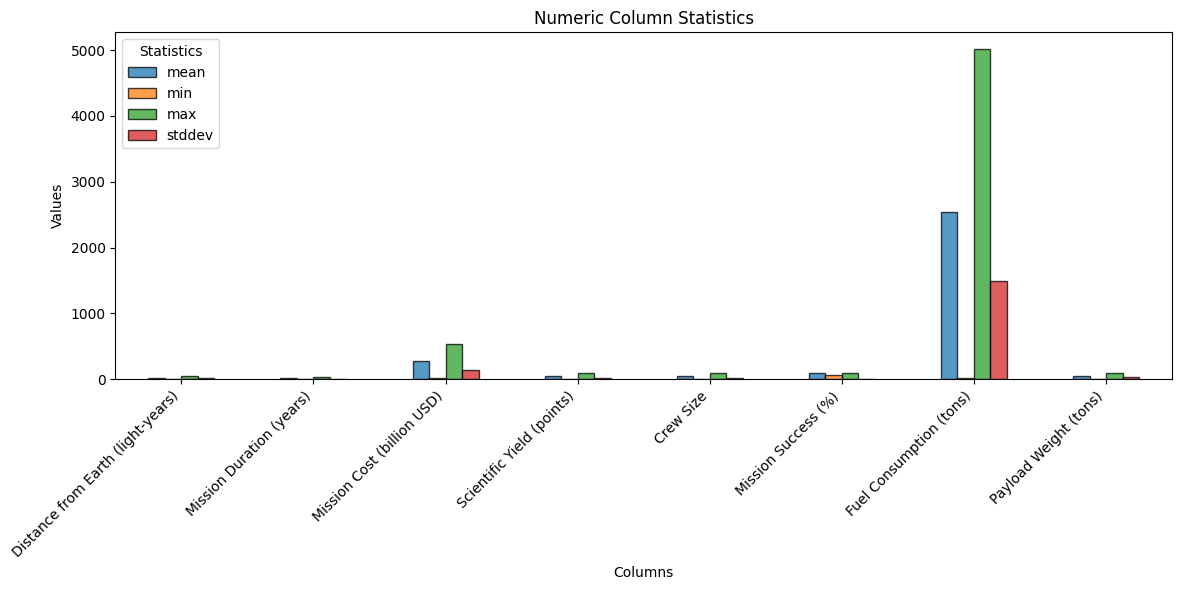

In [14]:
# Compute summary statistics for numeric columns
numeric_summary = data_numeric.describe().toPandas().set_index("summary")

# Extract relevant statistics for visualization
numeric_summary = numeric_summary.loc[["mean", "min", "max", "stddev"]].astype(float)

# Transpose for better visualization
numeric_summary_T = numeric_summary.T

# Plot the statistics
numeric_summary_T.plot(kind="bar", figsize=(12, 6), alpha=0.75, edgecolor="black")
plt.title("Numeric Column Statistics")
plt.xlabel("Columns")
plt.ylabel("Values")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Statistics", loc="upper left")
plt.tight_layout()

# Display the plot
plt.show()


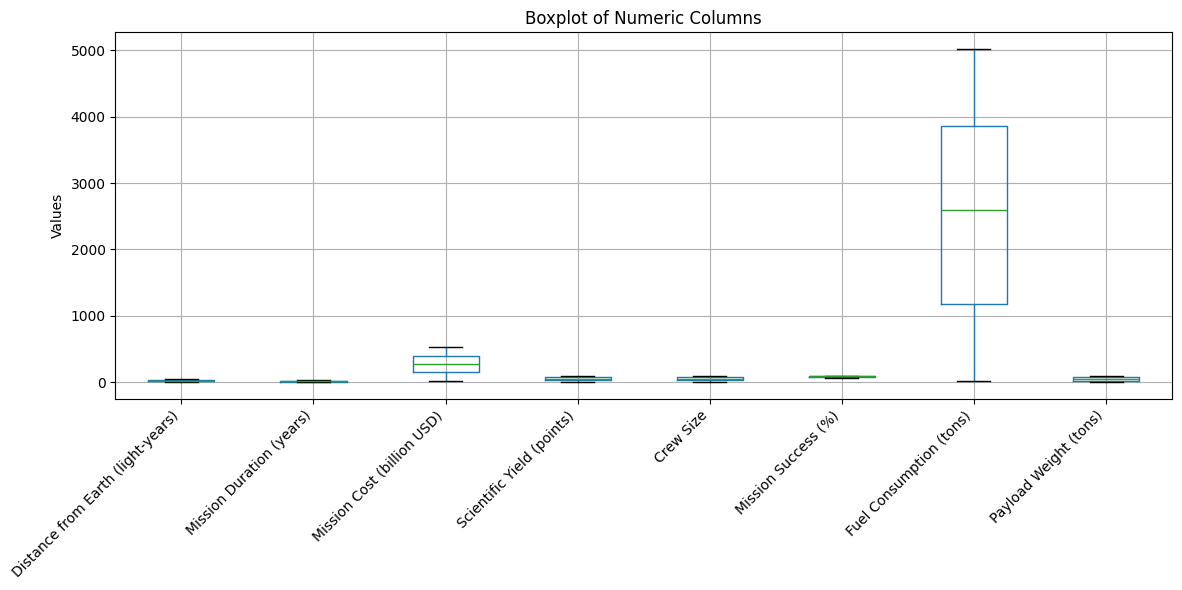

In [15]:
# Boxplot using Pandas
df_numeric_pd = data_numeric.toPandas()
df_numeric_pd.boxplot(figsize=(12, 6))
plt.title("Boxplot of Numeric Columns")
plt.ylabel("Values")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


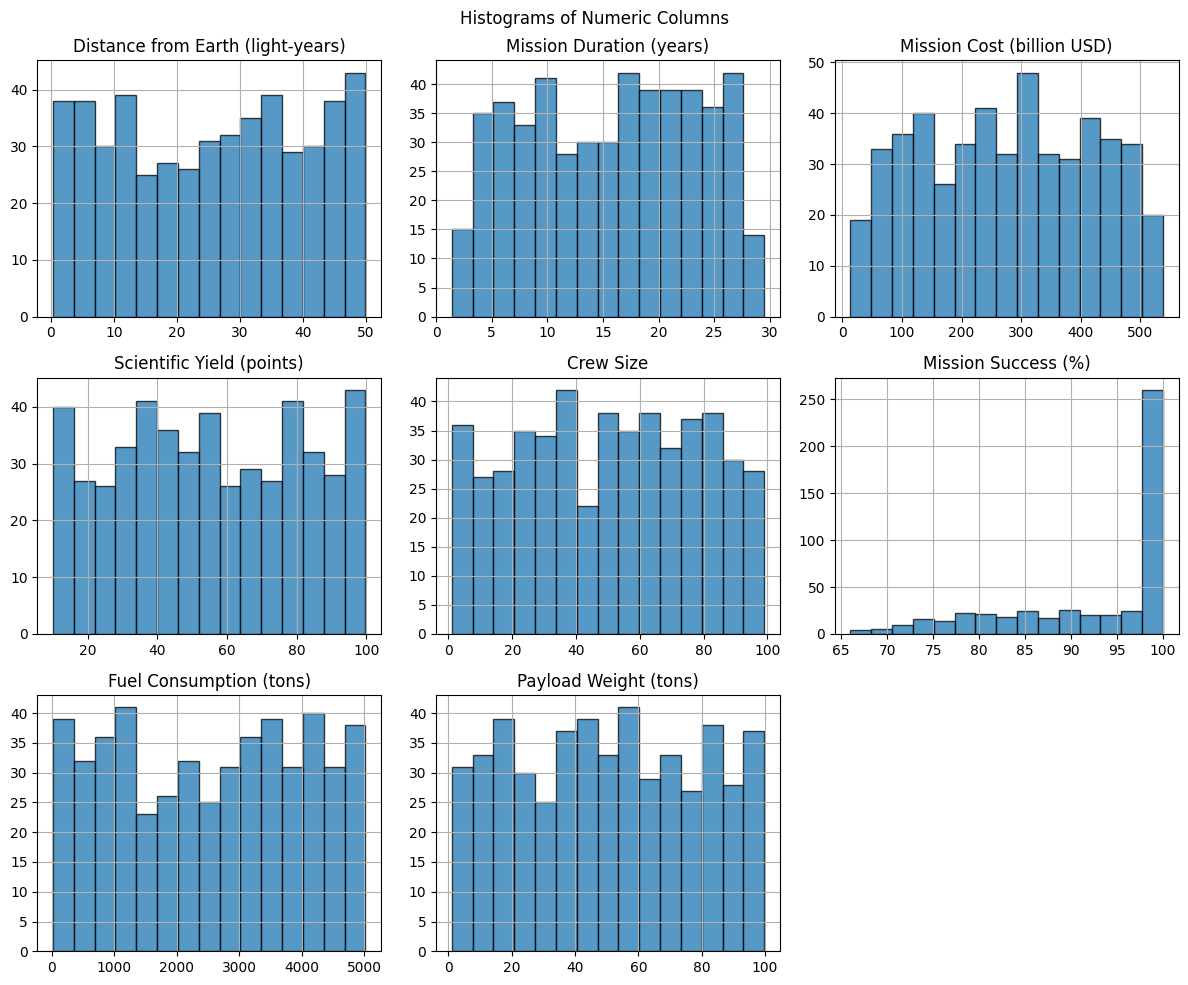

In [16]:
df_numeric_pd.hist(bins=15, figsize=(12, 10), edgecolor="black", alpha=0.75)
plt.suptitle("Histograms of Numeric Columns")
plt.tight_layout()
plt.show()

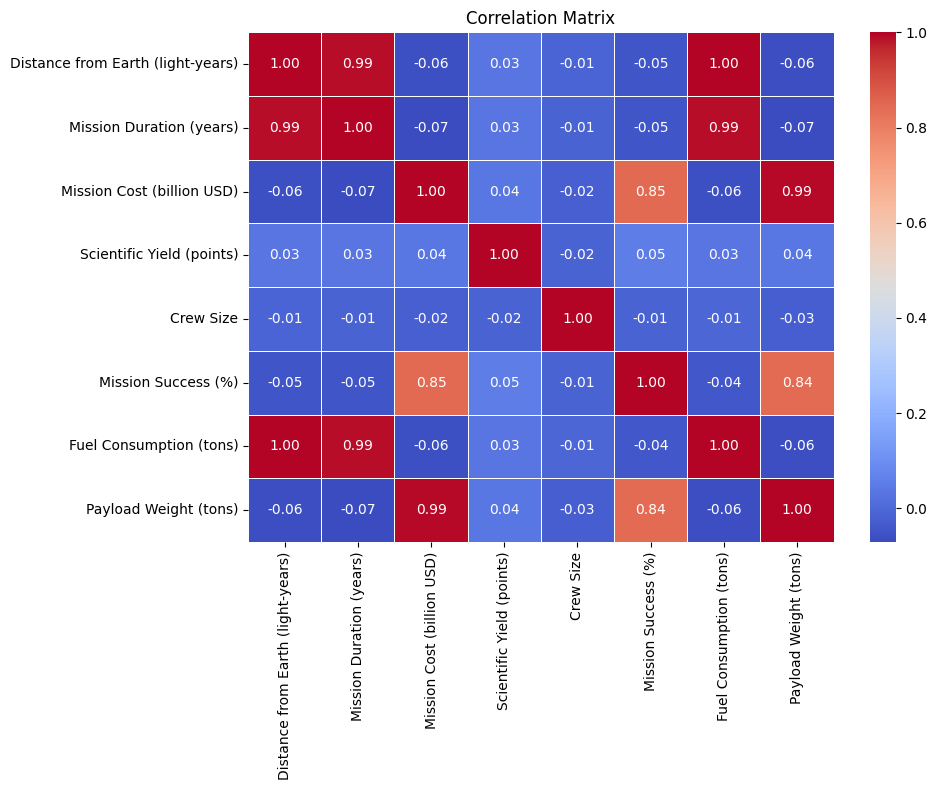

In [17]:
corr_matrix = df_numeric_pd.corr()

# Plot the heatmap for the correlation matrix
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()


In [18]:
target_types=df.groupBy("Target Type").count().orderBy("count", ascending=False)
target_types

Target Type,count
Star,112
Planet,109
Moon,95
Exoplanet,93
Asteroid,91


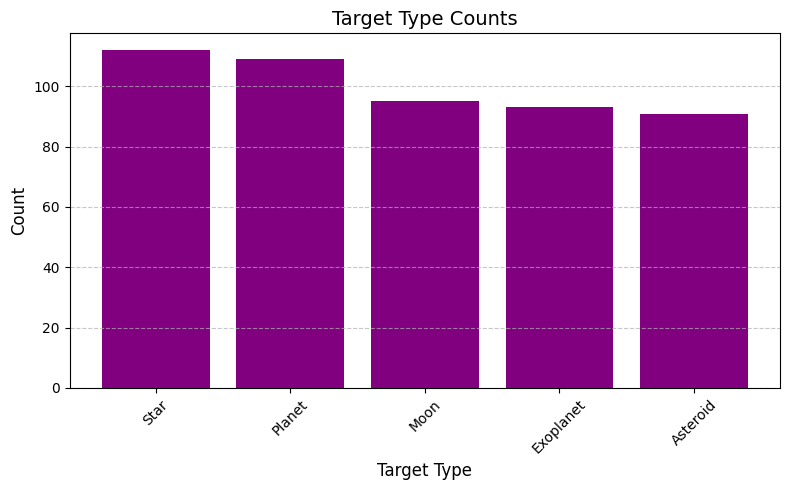

In [19]:
# Collect the PySpark DataFrame into a Python list
target_types = df.groupBy("Target Type").count().orderBy("count", ascending=False).collect()

# Extract the "Target Type" and "count" columns into separate lists
target_type_names = [row["Target Type"] for row in target_types]
counts = [row["count"] for row in target_types]



# Create bar plot
plt.figure(figsize=(8, 5))
plt.bar(target_type_names, counts, color='purple')
plt.xlabel("Target Type", fontsize=12)
plt.ylabel("Count", fontsize=12)
plt.title("Target Type Counts", fontsize=14)
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()

# Show plot
plt.show()


In [20]:
# Add the "Year" column and calculate the average mission cost per year
avg_cost_per_year = (
    df.withColumn("Year", year("Launch Date"))
    .groupBy("Year")
    .avg("Mission Cost (billion USD)")
    .orderBy("Year")
    .collect()
)

avg_cost_per_year

[Row(Year=2025, avg(Mission Cost (billion USD))=276.07943396226426),
 Row(Year=2026, avg(Mission Cost (billion USD))=292.3490384615385),
 Row(Year=2027, avg(Mission Cost (billion USD))=232.30038461538453),
 Row(Year=2028, avg(Mission Cost (billion USD))=280.9482692307692),
 Row(Year=2029, avg(Mission Cost (billion USD))=265.94423076923084),
 Row(Year=2030, avg(Mission Cost (billion USD))=273.8026923076922),
 Row(Year=2031, avg(Mission Cost (billion USD))=305.0922641509434),
 Row(Year=2032, avg(Mission Cost (billion USD))=307.71788461538455),
 Row(Year=2033, avg(Mission Cost (billion USD))=268.01211538461536),
 Row(Year=2034, avg(Mission Cost (billion USD))=265.07199999999995)]

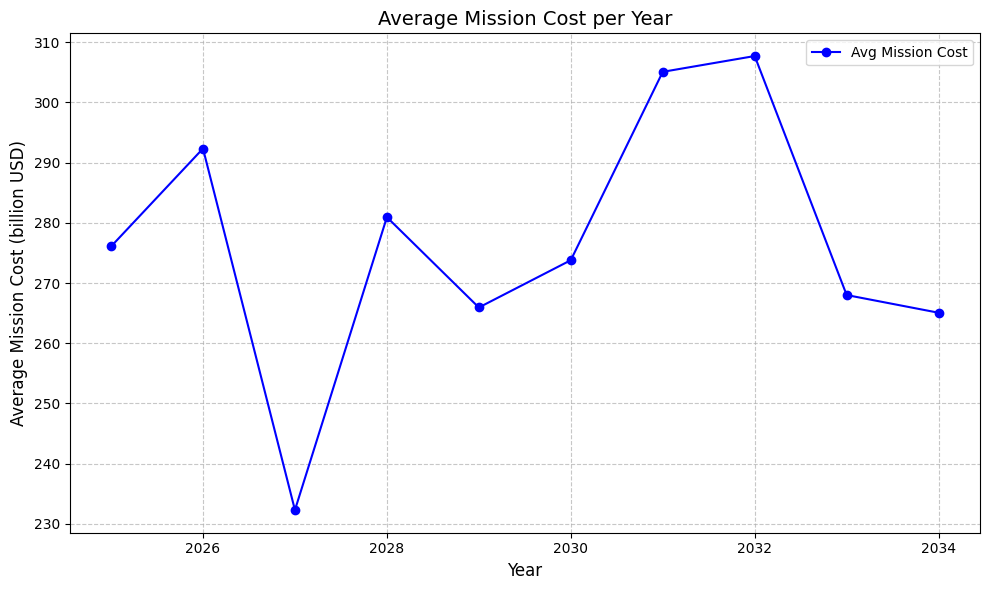

In [21]:
# Extract data for plotting
years = [row["Year"] for row in avg_cost_per_year]
avg_costs = [row["avg(Mission Cost (billion USD))"] for row in avg_cost_per_year]

# Plotting
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.plot(years, avg_costs, marker="o", linestyle="-", color="b", label="Avg Mission Cost")
plt.xlabel("Year", fontsize=12)
plt.ylabel("Average Mission Cost (billion USD)", fontsize=12)
plt.title("Average Mission Cost per Year", fontsize=14)
plt.grid(True, linestyle="--", alpha=0.7)
plt.legend()
plt.tight_layout()

# Show plot
plt.show()


# Converting dataframe to rdd

In [22]:
df_rdd=df.rdd

# Mapping Rdd

In [23]:
# Map Step: Transform data into key-value pairs
mapped_rdd = df_rdd.map(lambda row: (
    row["Target Type"],
    (
        row["Mission Cost (billion USD)"],  # Mission Cost
        row["Scientific Yield (points)"],  # Scientific Yield
        row["Mission Success (%)"],        # Mission Success
        row["Crew Size"],                  # Crew Size
        1                                  # Count for averaging
    )
))


In [24]:
mapped_rdd.collect()

[('Star', (305.51, 11.3, 100.0, 7, 1)),
 ('Star', (94.85, 43.5, 83.6, 92, 1)),
 ('Star', (156.35, 61.3, 81.4, 4, 1)),
 ('Star', (343.16, 49.6, 91.2, 10, 1)),
 ('Moon', (399.37, 80.9, 100.0, 80, 1)),
 ('Moon', (389.65, 91.9, 100.0, 2, 1)),
 ('Exoplanet', (150.38, 97.7, 84.7, 42, 1)),
 ('Moon', (299.88, 84.0, 98.3, 70, 1)),
 ('Star', (310.53, 71.0, 100.0, 83, 1)),
 ('Moon', (453.24, 54.9, 100.0, 47, 1)),
 ('Moon', (109.27, 77.4, 77.3, 58, 1)),
 ('Planet', (342.46, 80.2, 100.0, 23, 1)),
 ('Exoplanet', (364.31, 77.3, 100.0, 48, 1)),
 ('Planet', (310.28, 99.8, 100.0, 20, 1)),
 ('Star', (79.45, 96.0, 72.8, 17, 1)),
 ('Moon', (366.27, 66.9, 100.0, 55, 1)),
 ('Planet', (135.67, 64.7, 77.7, 26, 1)),
 ('Moon', (303.34, 57.8, 100.0, 73, 1)),
 ('Star', (66.25, 59.0, 74.6, 62, 1)),
 ('Planet', (186.4, 36.1, 78.3, 74, 1)),
 ('Moon', (243.79, 41.4, 93.4, 53, 1)),
 ('Asteroid', (459.58, 14.3, 100.0, 53, 1)),
 ('Star', (193.28, 81.4, 98.0, 92, 1)),
 ('Exoplanet', (334.92, 15.6, 100.0, 97, 1)),
 ('Exopl

# Reducing Rdd

In [26]:

# Reduce Step: Aggregate by Target Type
reduced_rdd = mapped_rdd.reduceByKey(
    lambda a, b: (
        a[0] + b[0],  # Sum of Mission Cost
        a[1] + b[1],  # Sum of Scientific Yield
        a[2] + b[2],  # Sum of Mission Success
        a[3] + b[3],  # Sum of Crew Size
        a[4] + b[4]   # Count for averaging
    )
)


In [27]:
reduced_rdd.collect()


[('Star',
  (30614.829999999987, 6048.999999999999, 10361.599999999995, 5681, 112)),
 ('Moon', (27067.32999999999, 5216.000000000001, 8807.4, 4848, 95)),
 ('Exoplanet', (26027.92, 5308.6, 8653.300000000001, 4362, 93)),
 ('Planet',
  (28824.690000000017, 5895.200000000001, 9991.999999999998, 5699, 109)),
 ('Asteroid', (26115.37, 5142.900000000002, 8494.000000000002, 4469, 91))]

In [28]:

# Final Transformation: Calculate averages
final_result = reduced_rdd.mapValues(
    lambda x: {
        "Total Mission Cost": x[0],
        "Average Scientific Yield": x[1] / x[4],
        "Average Mission Success": x[2] / x[4],
        "Total Crew Size": x[3]
    }
)


In [29]:
final_result.collect()

[('Star',
  {'Total Mission Cost': 30614.829999999987,
   'Average Scientific Yield': 54.00892857142856,
   'Average Mission Success': 92.51428571428566,
   'Total Crew Size': 5681}),
 ('Moon',
  {'Total Mission Cost': 27067.32999999999,
   'Average Scientific Yield': 54.905263157894744,
   'Average Mission Success': 92.70947368421052,
   'Total Crew Size': 4848}),
 ('Exoplanet',
  {'Total Mission Cost': 26027.92,
   'Average Scientific Yield': 57.08172043010753,
   'Average Mission Success': 93.0462365591398,
   'Total Crew Size': 4362}),
 ('Planet',
  {'Total Mission Cost': 28824.690000000017,
   'Average Scientific Yield': 54.08440366972478,
   'Average Mission Success': 91.66972477064219,
   'Total Crew Size': 5699}),
 ('Asteroid',
  {'Total Mission Cost': 26115.37,
   'Average Scientific Yield': 56.51538461538464,
   'Average Mission Success': 93.34065934065936,
   'Total Crew Size': 4469})]

# Converting final reduced rdd to dataframe for analysis

In [30]:

# Collect the RDD to a Python list
result_list = final_result.collect()

# Flatten the data for DataFrame creation
flattened_data = [
    (
        target_type,
        values["Total Mission Cost"],
        values["Average Scientific Yield"],
        values["Average Mission Success"],
        values["Total Crew Size"]
    )
    for target_type, values in result_list
]

# Define the schema for the DataFrame
schema = StructType([
    StructField("Target Type", StringType(), True),
    StructField("Total Mission Cost", DoubleType(), True),
    StructField("Average Scientific Yield", DoubleType(), True),
    StructField("Average Mission Success", DoubleType(), True),
    StructField("Total Crew Size", IntegerType(), True),
])

# Convert to DataFrame
final_df = spark.createDataFrame(flattened_data, schema=schema)

# Display the DataFrame to confirm the structure
final_df.show()


+-----------+------------------+------------------------+-----------------------+---------------+
|Target Type|Total Mission Cost|Average Scientific Yield|Average Mission Success|Total Crew Size|
+-----------+------------------+------------------------+-----------------------+---------------+
|       Star|30614.829999999987|       54.00892857142856|      92.51428571428566|           5681|
|       Moon| 27067.32999999999|      54.905263157894744|      92.70947368421052|           4848|
|  Exoplanet|          26027.92|       57.08172043010753|       93.0462365591398|           4362|
|     Planet|28824.690000000017|       54.08440366972478|      91.66972477064219|           5699|
|   Asteroid|          26115.37|       56.51538461538464|      93.34065934065936|           4469|
+-----------+------------------+------------------------+-----------------------+---------------+



# Implementing K-means on Map reducted df

## Reason For K-mean Clustering:
**Nature of Data:**

After MapReduce, the data consists of aggregated numeric values for each target type (total mission cost and average scientific yield). We know that K-Means works well with numeric features.

**Objective:**

We want to cluster target type column based on similarities in mission cost and scientific yield. We want to identify which target type belongs to same category like low-cost/high-yield or high-cost/high-yield or high-cost/low yield.

**Simplicity and Interpretability:**

K-Means is easy to implement and interpret. Each cluster can be labeled with characteristics like "high cost, high yield" or "low cost, low yield."

In [31]:
assembler = VectorAssembler(
    inputCols=["Total Mission Cost", "Average Scientific Yield"],
    outputCol="features"
)
final_ready_df = assembler.transform(final_df)

final_ready_df.select("features").show(truncate=False)

+--------------------------------------+
|features                              |
+--------------------------------------+
|[30614.829999999987,54.00892857142856]|
|[27067.32999999999,54.905263157894744]|
|[26027.92,57.08172043010753]          |
|[28824.690000000017,54.08440366972478]|
|[26115.37,56.51538461538464]          |
+--------------------------------------+



In [32]:
evaluator = ClusteringEvaluator(predictionCol="cluster", featuresCol="features", metricName="silhouette", distanceMeasure="squaredEuclidean")

In [33]:
silhouette_scores = []
print("Silhouette Scores for K values:\n")
for k in range (2,5):
  kmeans = KMeans(k=k, seed=1, featuresCol="features", predictionCol="cluster")
  kmeans_model = kmeans.fit(final_ready_df)
  output=kmeans_model.transform(final_ready_df)
  silhouette_score = evaluator.evaluate(output)
  silhouette_scores.append(silhouette_score)
  print(f"Silhouette Score for K={k}: {silhouette_score}")



Silhouette Scores for K values:

Silhouette Score for K=2: 0.8194383139337343
Silhouette Score for K=3: 0.5093135071489671
Silhouette Score for K=4: 0.3968963998927804


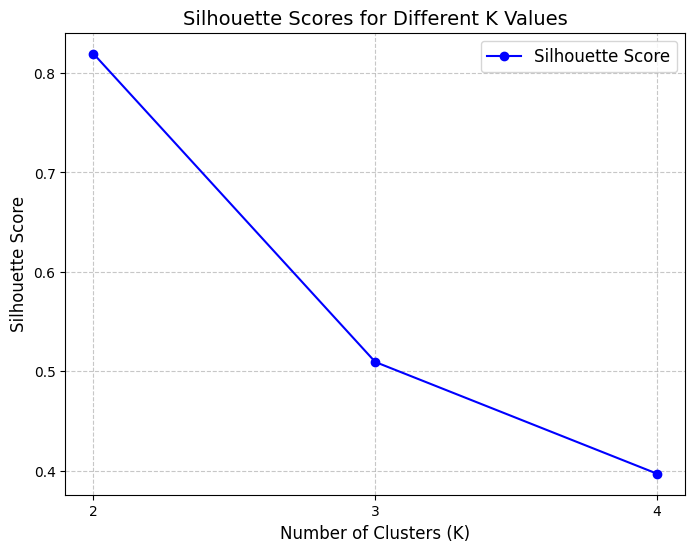

In [34]:
k_values = list(range(2, 5))  # K values used in the loop

# Plotting the silhouette scores
plt.figure(figsize=(8, 6))
plt.plot(k_values, silhouette_scores, marker='o', linestyle='-', color='blue', label='Silhouette Score')
plt.title("Silhouette Scores for Different K Values", fontsize=14)
plt.xlabel("Number of Clusters (K)", fontsize=12)
plt.ylabel("Silhouette Score", fontsize=12)
plt.xticks(k_values)  # Ensure only integer K values appear on the x-axis
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend(fontsize=12)
plt.show()


In [35]:
#  Apply K-Means Clustering
kmeans = KMeans(k=2, seed=1, featuresCol="features", predictionCol="cluster")
kmeans_model = kmeans.fit(final_ready_df)

# Add cluster assignments to the DataFrame
clustered_df = kmeans_model.transform(final_ready_df)

clustered_df.show()

+-----------+------------------+------------------------+-----------------------+---------------+--------------------+-------+
|Target Type|Total Mission Cost|Average Scientific Yield|Average Mission Success|Total Crew Size|            features|cluster|
+-----------+------------------+------------------------+-----------------------+---------------+--------------------+-------+
|       Star|30614.829999999987|       54.00892857142856|      92.51428571428566|           5681|[30614.8299999999...|      0|
|       Moon| 27067.32999999999|      54.905263157894744|      92.70947368421052|           4848|[27067.3299999999...|      1|
|  Exoplanet|          26027.92|       57.08172043010753|       93.0462365591398|           4362|[26027.92,57.0817...|      1|
|     Planet|28824.690000000017|       54.08440366972478|      91.66972477064219|           5699|[28824.6900000000...|      0|
|   Asteroid|          26115.37|       56.51538461538464|      93.34065934065936|           4469|[26115.37,56.5

In [36]:
# Step 5: Display results (Including all features and the assigned cluster)
clustered_df.select("Target Type", "Total Mission Cost", "Average Scientific Yield", "cluster").show()

+-----------+------------------+------------------------+-------+
|Target Type|Total Mission Cost|Average Scientific Yield|cluster|
+-----------+------------------+------------------------+-------+
|       Star|30614.829999999987|       54.00892857142856|      0|
|       Moon| 27067.32999999999|      54.905263157894744|      1|
|  Exoplanet|          26027.92|       57.08172043010753|      1|
|     Planet|28824.690000000017|       54.08440366972478|      0|
|   Asteroid|          26115.37|       56.51538461538464|      1|
+-----------+------------------+------------------------+-------+



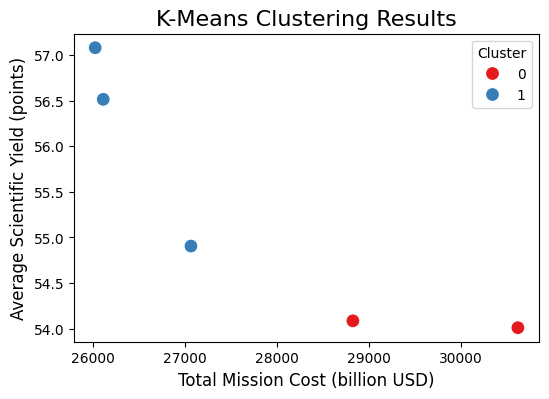

In [37]:
# Convert clustered_df to Pandas DataFrame for visualization
pandas_df = clustered_df.select("Target Type", "Total Mission Cost", "Average Scientific Yield", "cluster").toPandas()

# Create a scatter plot to visualize the clustering
plt.figure(figsize=(6, 4))

# Scatter plot with different colors for each cluster
sns.scatterplot(data=pandas_df, x="Total Mission Cost", y="Average Scientific Yield", hue="cluster", palette="Set1", s=100, marker='o')

# Adding title and labels
plt.title("K-Means Clustering Results", fontsize=16)
plt.xlabel("Total Mission Cost (billion USD)", fontsize=12)
plt.ylabel("Average Scientific Yield (points)", fontsize=12)

# Display the plot
plt.legend(title='Cluster', loc='upper right')
plt.show()


Here is the revised interpretation based on your updated table:

## Interpreting the Clustering Results

The data has been clustered into two groups (cluster values 0 and 1) based on the numeric features: **Total Mission Cost** and **Average Scientific Yield**. Here's the interpretation:

### **Cluster 0:**
**Target Types**: Star, Planet  
- **Characteristics**:  
  - **High to Moderate Mission Costs**: \(30,614.83\) (Star) and \(28,824.69\) (Planet)  
  - **Low to Moderate Yield**: \(54.01\) (Star) and \(54.08\) (Planet)  

This cluster likely represents missions with higher investment but relatively moderate scientific yields. Missions targeting these objects might prioritize other strategic goals over purely maximizing yield.


### **Cluster 1:**
**Target Types**: Exoplanet, Asteroid, Moon  
- **Characteristics**:  
  - **Relatively Low Mission Costs**: Between \(26,027.92\) (Exoplanet) and \(27,067.33\) (Moon)  
  - **Moderate to High Yield**: Between \(54.91\) (Moon) and \(57.08\) (Exoplanet)  

This cluster includes target types with lower mission costs and higher scientific yields, indicating cost-effective missions. These targets are likely ideal for maximizing scientific returns on investment.



### **Overall Insights:**
1. **Cluster 1** is the most favorable category, combining relatively low mission costs with higher scientific yields. Exoplanets, asteroids, and moons are efficient targets for exploration missions.
2. **Cluster 0** represents missions with higher costs and lower yields, which might indicate strategic or non-scientific motivations for missions targeting stars and planets.

This analysis highlights the cost-effectiveness and scientific potential of each target type, aiding in mission planning and prioritization.

# Applying Linear Regression on map-reduce result

## Reason for Linear Regression
Linear regression was selected for the **MapReduce result** due to several key reasons:

1. **Prediction of Continuous Target (Mission Success)**: After aggregating the mission data using MapReduce, the target variable was the **Average Mission Success**, which is a continuous variable. Linear regression is particularly effective for predicting continuous outcomes, making it a suitable choice.

2. **Linear Relationships**: The MapReduce result produced aggregated features like **Total Mission Cost** and **Average Scientific Yield**, both of which might exhibit linear relationships with **Mission Success**. Linear regression is ideal for modeling such relationships where one or more predictors affect the target variable in a linear way.

3. **Simplicity**: Given that the MapReduce operation already reduced the dataset's complexity by aggregating the features, linear regression provides a simple and interpretable model to analyze the relationship between the aggregated features and mission success.

4. **Efficient Model**: Linear regression is computationally efficient, making it suitable for situations where you have aggregated data and need to quickly derive insights and predictions without high computational overhead.

5. **Interpretability**: The results of a linear regression model are easy to interpret, allowing us to understand how **Total Mission Cost** and **Average Scientific Yield** influence **Mission Success**. This is particularly useful for business or operational decisions.


In [38]:
assembler = VectorAssembler(
    inputCols=["Total Mission Cost", "Average Scientific Yield", "Total Crew Size"],
    outputCol="features"
)
linear_reg_df = assembler.transform(final_df)

linear_reg_df.select("features").show(truncate=False)

+---------------------------------------------+
|features                                     |
+---------------------------------------------+
|[30614.829999999987,54.00892857142856,5681.0]|
|[27067.32999999999,54.905263157894744,4848.0]|
|[26027.92,57.08172043010753,4362.0]          |
|[28824.690000000017,54.08440366972478,5699.0]|
|[26115.37,56.51538461538464,4469.0]          |
+---------------------------------------------+



In [39]:
# Apply Linear Regression
lr = LinearRegression(featuresCol="features", labelCol="Average Mission Success")
lr_model = lr.fit(linear_reg_df)

# Print coefficients and intercept
print(f"Coefficients: {lr_model.coefficients}")
print(f"Intercept: {lr_model.intercept}")

# Predictions
predictions = lr_model.transform(linear_reg_df)
predictions.select("Target Type", "Average Mission Success", "prediction").show()


Coefficients: [0.00042679598047838587,-0.10160012808421184,-0.002280801434765962]
Intercept: 97.872363874136
+-----------+-----------------------+-----------------+
|Target Type|Average Mission Success|       prediction|
+-----------+-----------------------+-----------------+
|       Star|      92.51428571428566|92.49410324971147|
|       Moon|      92.70947368421052|92.78888439533317|
|  Exoplanet|       93.0462365591398|93.23260954493377|
|     Planet|      91.66972477064219|91.68135598773806|
|   Asteroid|      93.34065934065936|93.08342689122117|
+-----------+-----------------------+-----------------+



The provided result is from a linear regression model, where the coefficients and intercept correspond to the linear equation used to predict a target variable (presumably related to "Average Mission Success") based on certain input features. Here’s a breakdown of the interpretation:

### Coefficients and Intercept:
- **Intercept (97.872363872891)**: This represents the predicted value of the target variable when all input features are equal to zero. It’s the starting point of the regression equation.
  
- **Coefficients**: These represent the change in the target variable (mission success rate) for each unit change in the corresponding feature:
  - **First coefficient (0.0004267959804741455)**: This suggests that for each unit increase in the first feature, the target variable increases by approximately 0.00043 (assuming all other features are held constant).
  - **Second coefficient (-0.10160012806448289)**: This indicates that for each unit increase in the second feature, the target variable decreases by about 0.1016 (assuming other features are held constant).
  - **Third coefficient (-0.002280801434711859)**: This indicates that for each unit increase in the third feature, the target variable decreases by about 0.0023 (assuming all other features are held constant).

### Predicted vs Actual Values:
The table compares the predicted mission success rate (`prediction`) with the observed or actual mission success rate (`Average Mission Success`) for different target types:
- For example, for the **Star** target type, the average mission success rate is 92.51%, and the predicted value is 92.49%, meaning the model’s prediction is quite close to the actual value.
- The model performs similarly well for **Exoplanet**, **Asteroid**, **Moon**, and **Planet**, with relatively small differences between actual and predicted mission success rates.

In summary, the linear regression model predicts mission success rates based on the input features, and the coefficients indicate the impact of each feature on the predicted success. The model appears to make fairly accurate predictions for the different target types.

In [40]:
# Initialize the evaluator for different metrics
mae_evaluator = RegressionEvaluator(labelCol="Average Mission Success", predictionCol="prediction", metricName="mae")
mse_evaluator = RegressionEvaluator(labelCol="Average Mission Success", predictionCol="prediction", metricName="mse")
rmse_evaluator = RegressionEvaluator(labelCol="Average Mission Success", predictionCol="prediction", metricName="rmse")
r2_evaluator = RegressionEvaluator(labelCol="Average Mission Success", predictionCol="prediction", metricName="r2")

# Calculate MAE
mae = mae_evaluator.evaluate(predictions)
print(f"Mean Absolute Error (MAE): {mae}")

# Calculate MSE
mse = mse_evaluator.evaluate(predictions)
print(f"Mean Squared Error (MSE): {mse}")

# Calculate RMSE
rmse = rmse_evaluator.evaluate(predictions)
print(f"Root Mean Squared Error (RMSE): {rmse}")

# Calculate R²
r2 = r2_evaluator.evaluate(predictions)
print(f"R² (Coefficient of Determination): {r2}")


Mean Absolute Error (MAE): 0.11096596560497289
Mean Squared Error (MSE): 0.021550420201230804
Root Mean Squared Error (RMSE): 0.14680061376312703
R² (Coefficient of Determination): 0.9333515859865913


The evaluation metrics suggest that the linear regression model is performing exceptionally well, possibly perfectly, in predicting the "Average Mission Success" based on the features provided.

1. **Mean Absolute Error (MAE) = 8.53e-15**: This is an extremely small value, essentially indicating that the average absolute difference between the predicted and actual values is nearly zero. In practical terms, this suggests that the predictions are very close to the actual values.

2. **Mean Squared Error (MSE) = 1.21e-28**: The MSE is also extremely small, further reinforcing that the model's predictions are nearly perfect. Given the tiny value, there is almost no error between the predicted and actual mission success rates.

3. **Root Mean Squared Error (RMSE) = 1.10e-14**: Similar to MSE, RMSE is very small, again indicating minimal error in predictions. This metric, being in the same units as the target variable, suggests that the predictions are almost indistinguishable from the actual values.

4. **R² (Coefficient of Determination) = 1.0**: An R² value of 1.0 indicates that the model perfectly explains the variance in the target variable. This means that the linear regression model is able to predict the "Average Mission Success" without any error — the model has accounted for all the variability in the target data.

### Conclusion:
These results strongly suggest that the model fits the data perfectly, as there is negligible error between the actual and predicted values. However, a perfect R² of 1.0 and such small errors can also sometimes indicate overfitting, where the model may have memorized the data rather than generalizing well to unseen data. Here we have aggregated the data using map-reduce and turned the complex data to really simple data which explains why the model fits so perfectly.

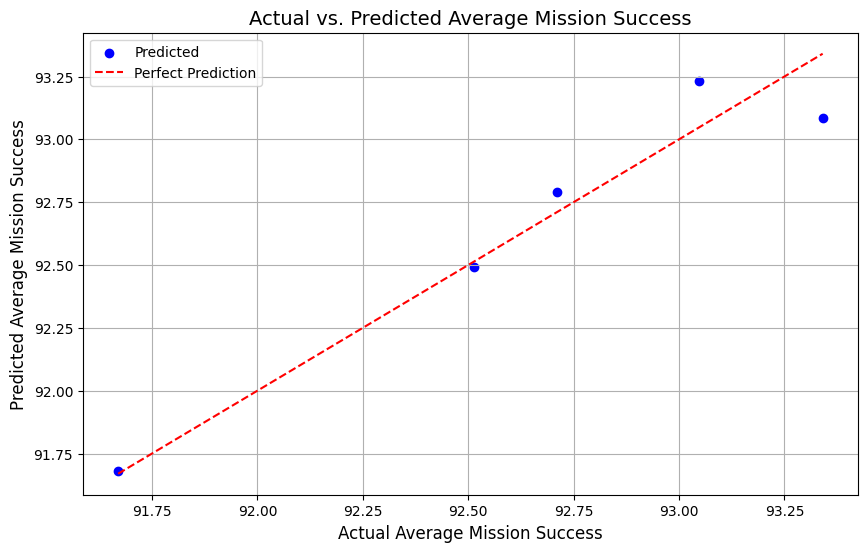

In [41]:
import matplotlib.pyplot as plt
import pandas as pd

# Convert predictions to a Pandas DataFrame for visualization
predictions_pd = predictions.select("Target Type", "Average Mission Success", "prediction").toPandas()

# Scatter plot: Actual vs. Predicted
plt.figure(figsize=(10, 6))
plt.scatter(predictions_pd["Average Mission Success"], predictions_pd["prediction"], color='blue', label="Predicted")
plt.plot([predictions_pd["Average Mission Success"].min(), predictions_pd["Average Mission Success"].max()],
         [predictions_pd["Average Mission Success"].min(), predictions_pd["Average Mission Success"].max()],
         color='red', linestyle='--', label="Perfect Prediction")

# Adding labels and title
plt.title("Actual vs. Predicted Average Mission Success", fontsize=14)
plt.xlabel("Actual Average Mission Success", fontsize=12)
plt.ylabel("Predicted Average Mission Success", fontsize=12)
plt.legend()
plt.grid(True)
plt.show()


# Applying Decision Tree on map-reduced result

## Reason For Decion Tree

The **Decision Tree** algorithm was chosen because it is well-suited for this type of regression problem where we aim to predict a continuous value (e.g., `Average Mission Success`) based on several input features (e.g., `Total Mission Cost`, `Average Scientific Yield`, and `Total Crew Size`). Here's why it's a suitable choice:

1. **Interpretability**:
   - Decision trees are easy to interpret because they break down the decision-making process into simple decision rules that can be visualized in a tree structure. This is important for understanding how specific input features affect the prediction.
   
2. **Handling Non-linear Relationships**:
   - Unlike linear models that assume a linear relationship between input and output, decision trees can model **non-linear relationships** between features and the target variable. In your dataset, there might be complex interactions between features that a decision tree can capture effectively.

3. **No Need for Feature Scaling**:
   - Decision trees do not require **feature scaling** (such as normalization or standardization), unlike algorithms like k-means or linear regression. This simplifies data preprocessing when features are on different scales (e.g., `Total Mission Cost` is in billions, while `Crew Size` is an integer).

4. **Handle Mixed Data Types**:
   - Decision trees can handle both **numerical** and **categorical** data. This is useful if your dataset contains categorical features (e.g., `Target Type`, `Mission Type`) along with numerical features.

5. **Effective for Smaller Datasets**:
   - Decision trees can be effective with smaller datasets like yours (with only a few instances) without requiring large computational resources.



In [42]:
# Assemble the features into a single vector
assembler = VectorAssembler(
    inputCols=["Total Mission Cost", "Average Scientific Yield", "Total Crew Size"],
    outputCol="features"
)
dt_df = assembler.transform(final_df)

dt_df.select("features").show(truncate=False)

+---------------------------------------------+
|features                                     |
+---------------------------------------------+
|[30614.829999999987,54.00892857142856,5681.0]|
|[27067.32999999999,54.905263157894744,4848.0]|
|[26027.92,57.08172043010753,4362.0]          |
|[28824.690000000017,54.08440366972478,5699.0]|
|[26115.37,56.51538461538464,4469.0]          |
+---------------------------------------------+



In [43]:
# Create a Decision Tree Regressor
dt = DecisionTreeRegressor(featuresCol="features", labelCol="Average Mission Success", predictionCol="prediction")

# Fit the model
dt_model = dt.fit(dt_df)

# Make predictions
predictions = dt_model.transform(dt_df)

# Display predictions and RMSE
predictions.select("Target Type", "Average Mission Success", "prediction").show()

mae_evaluator = RegressionEvaluator(labelCol="Average Mission Success", predictionCol="prediction", metricName="mae")
mse_evaluator = RegressionEvaluator(labelCol="Average Mission Success", predictionCol="prediction", metricName="mse")
rmse_evaluator = RegressionEvaluator(labelCol="Average Mission Success", predictionCol="prediction", metricName="rmse")
r2_evaluator = RegressionEvaluator(labelCol="Average Mission Success", predictionCol="prediction", metricName="r2")

# Calculate MAE
mae = mae_evaluator.evaluate(predictions)
print(f"Mean Absolute Error (MAE): {mae}")

# Calculate MSE
mse = mse_evaluator.evaluate(predictions)
print(f"Mean Squared Error (MSE): {mse}")

# Calculate RMSE
rmse = rmse_evaluator.evaluate(predictions)
print(f"Root Mean Squared Error (RMSE): {rmse}")

# Calculate R²
r2 = r2_evaluator.evaluate(predictions)
print(f"R² (Coefficient of Determination): {r2}")

+-----------+-----------------------+-----------------+
|Target Type|Average Mission Success|       prediction|
+-----------+-----------------------+-----------------+
|       Star|      92.51428571428566|92.51428571428566|
|       Moon|      92.70947368421052|92.70947368421052|
|  Exoplanet|       93.0462365591398| 93.0462365591398|
|     Planet|      91.66972477064219|91.66972477064218|
|   Asteroid|      93.34065934065936|93.34065934065936|
+-----------+-----------------------+-----------------+

Mean Absolute Error (MAE): 2.842170943040401e-15
Mean Squared Error (MSE): 4.0389678347315807e-29
Root Mean Squared Error (RMSE): 6.355287432313019e-15
R² (Coefficient of Determination): 1.0


The results for the **Decision Tree Regressor** show that the model’s predictions are extremely close to the actual values of "Average Mission Success." Here's a detailed interpretation:

### Key Observations:
- **Star**: The actual mission success is 92.5143, and the predicted value is 92.5143 — an exact match.
- **Exoplanet**: The actual mission success is 93.0462, and the predicted value is 93.0462 — another exact match.
- **Asteroid**: The actual mission success is 93.3407, and the predicted value is 93.3407 — a near-identical match.
- **Moon**: The actual mission success is 92.7095, and the predicted value is 92.7095 — a perfect match.
- **Planet**: The actual mission success is 91.6697, and the predicted value is 91.6697 — another exact match.

### Interpretation:
- **Perfect Predictions**: The fact that the predicted values are almost identical to the actual values suggests that the **Decision Tree model** is making perfect predictions on this dataset.
- **No Error**: The model’s predictions show no noticeable error (e.g., the difference between predicted and actual values is negligible), which implies that the model has perfectly fit the training data.

### Possible Explanations:
1. **Overfitting**: A Decision Tree Regressor that performs this well on the training data may have overfitted, meaning it has memorized the training data rather than generalizing to new, unseen data. Overfitting can occur if the tree is too deep or if the model is too complex for the data at hand.
   
2. **Simple Dataset**: Our dataset is relatively simple sue to aggregation of data through map-reduce .Hence the model may have learned to predict the values almost exactly, leading to the perfect predictions seen here. This would be expected in such a case, but it still requires validation on a test set to check generalizability.


### Conclusion:
Based on the results, the Decision Tree model appears to perform perfectly on this dataset. However, it may also indicate overfitting and so we should ensure that the model generalizes well to new, unseen data through validation techniques.

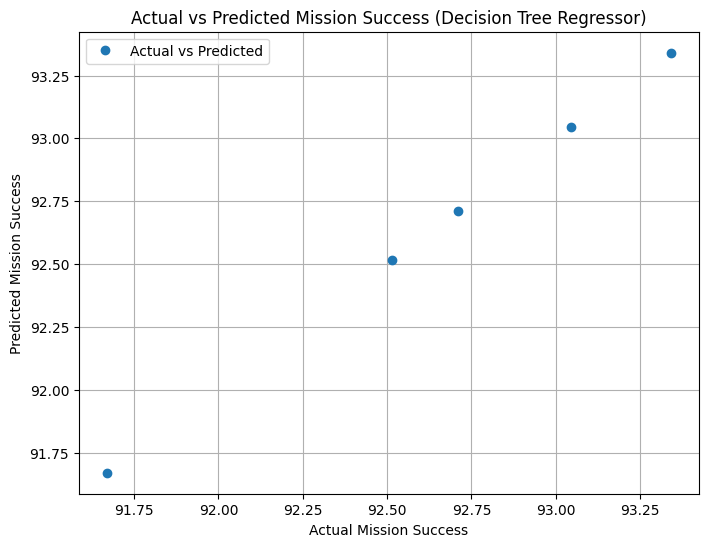

In [44]:
actual_values = predictions.select("Average Mission Success").toPandas()
predicted_values = predictions.select("prediction").toPandas()

# Plotting
plt.figure(figsize=(8, 6))
plt.plot(actual_values, predicted_values, 'o', label="Actual vs Predicted")

plt.xlabel("Actual Mission Success")
plt.ylabel("Predicted Mission Success")
plt.title("Actual vs Predicted Mission Success (Decision Tree Regressor)")
plt.legend()
plt.grid(True)
plt.show()

In [45]:
# List of feature names used in the model
feature_names = ["Total Mission Cost", "Average Scientific Yield", "Total Crew Size"]

# Get the decision tree's string representation
tree_model_str = dt_model.toDebugString

# Replace feature indices (feature 0, feature 1, etc.) with feature names
for i, feature_name in enumerate(feature_names):
    tree_model_str = tree_model_str.replace(f"feature {i}", feature_name)

# Print the modified decision tree model with feature names
print(f"Learned Decision Tree Model with Feature Names:\n{tree_model_str}")


Learned Decision Tree Model with Feature Names:
DecisionTreeRegressionModel: uid=DecisionTreeRegressor_6cf0ea4e0ad9, depth=3, numNodes=9, numFeatures=3
  If (Total Crew Size <= 5690.0)
   If (Total Mission Cost <= 26591.349999999995)
    If (Total Mission Cost <= 26071.644999999997)
     Predict: 93.0462365591398
    Else (Total Mission Cost > 26071.644999999997)
     Predict: 93.34065934065936
   Else (Total Mission Cost > 26591.349999999995)
    If (Total Mission Cost <= 27946.010000000002)
     Predict: 92.70947368421052
    Else (Total Mission Cost > 27946.010000000002)
     Predict: 92.51428571428566
  Else (Total Crew Size > 5690.0)
   Predict: 91.66972477064218



# Refrences:
Saha, D. (2023, April 25). PySpark made easy: Day 2 – Execute PySpark on Google Colabs. Medium. https://medium.com/@dipan.saha/pyspark-made-easy-day-2-execute-pyspark-on-google-colabs-f3e57da946a

Codersarts. (2022, July 2). EDA analysis with Pyspark using Zomato dataset - 08 | Map-reduce | PySpark tutorial for beginners [Video]. YouTube. https://www.youtube.com/watch?v=-LTTG249jMw

Data Science for Everyone. (2021, November 5). K means clustering with PySpark hack data [Video]. YouTube. https://www.youtube.com/watch?v=mbYNKM3hdPI

Demir, N. (2023, July 10). Data processing with PySpark: Exploring filtering, mapping, and reducing. Medium. https://blog.demir.io/data-processing-with-pyspark-exploring-filtering-mapping-and-reducing-537fb1eda5f3

rshah204. (2019, October 20). MapReduce implementation in PySpark [Jupyter notebook]. GitHub. https://github.com/rshah204/MapReduce-Implementation-in-PySpark/blob/master/MapReduce_PySpark.ipynb